# Chapitre 7 - Exercices 7.7 à 7.12

Ces exercices portent sur la seconde moitié du chapitre : LoRA, fusion de modèles et
tactiques de finetuning.

- **7.7** : compter les paramètres LoRA (GPT-3, Llama 2, service multi-LoRA) et repérer
  une incohérence dans un tableau ;
- **7.8** : LoRA à la main : initialisation, gradients, rang, coût de la version non
  fusionnée ;
- **7.9** : quel rang pour notre tâche ? (mini-lab : LoRA r = 1, 4, 32 sur Qwen2.5-0.5B) ;
- **7.10** : soupes de modèles (moyenner plusieurs finetunings d'une même tâche) ;
- **7.11** : SLERP : démonstrations et fusion en cascade de trois modèles ;
- **7.12** : accumulation de gradient, normalisation par token et poids de la perte du
  prompt.

In [1]:
import gc
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from aie.plotting import INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT, annotate_bars
from aie.diagrams import Diagram
from aie import llm
from aie import ch07_finetuning as c7

warnings.filterwarnings("ignore")
c7.setup_style()
llm.seed_everything(0)
GB = 1e9

## Exercice 7.7 : Compter les paramètres LoRA

**Énoncé.**

1. Retrouver le calcul du livre pour GPT-3 175B (96 couches, $d = 12\,288$) : LoRA de rang
   2 sur $W_q, W_k, W_v, W_o$. Combien de paramètres pour le rang 8 sur $W_q$ seul ?
2. Le tableau 7-6 du livre annonce, pour Llama 2-13B (40 couches, $d = 5\,120$) et
   « $r = 2$, matrices query et key », 3,28 M paramètres et 6,55 Mo. Vérifier. Que
   constate-t-on ? Même vérification pour la ligne GPT-3 (18,87 M).
3. Service multi-LoRA (section *Serving LoRA adapters*) : avec une matrice $4096 \times 4096$
   et $r = 8$, comparer le stockage de 100 modèles fusionnés et de 1 base + 100
   adaptateurs. À partir de combien de clients l'option séparée est-elle 10 fois plus
   économe ?

**Rappels.** Cours 3, sections 3 et 5 : un adaptateur de rang $r$ sur une matrice
$d_{out} \times d_{in}$ a $r(d_{in} + d_{out})$ paramètres ; on l'applique à chaque couche.

**Solution.**

*1.* Par matrice : $2 \times (12\,288 + 12\,288) = 49\,152$ ; quatre matrices, 96 couches :
$49\,152 \times 4 \times 96 = 18\,874\,368$. Rang 8 sur $W_q$ seul :
$8 \times 24\,576 \times 96 = 18\,874\,368$ : exactement le même budget, c'était le but.

*2.* Llama 2-13B, $r = 2$ sur $W_q$ et $W_k$ : $2 \times 10\,240 \times 2 \times 40 = 1\,638\,400$
paramètres, soit **1,64 M**, pas 3,28 M. Les 3,28 M correspondent aux **quatre** matrices
d'attention ($\times 2$). Même constat pour GPT-3 : 18,87 M est le nombre pour quatre
matrices, $W_q, W_k$ seuls donnent 9,44 M. Les mémoires (6,55 Mo, 37,7 Mo) sont cohérentes
avec les nombres annoncés à 2 octets par paramètre. Le libellé « query & key » de la
colonne semble donc erroné, ou les nombres correspondent à quatre matrices ; la conclusion
du tableau (l'adaptateur est minuscule devant les poids) reste vraie.

*3.* Fusionnés : $100 \times 16{,}78$ M $= 1{,}68$ Md ; séparés :
$16{,}78\text{ M} + 100 \times 65\,536 = 23{,}3$ M, 72 fois moins. Le rapport vaut
$n \cdot 16{,}78\text{M} / (16{,}78\text{M} + 65\,536\, n)$ : il dépasse 10 dès $n \ge 11$.

In [2]:
gpt3 = {"hidden_size": 12288, "num_attention_heads": 96, "intermediate_size": 49152, "num_hidden_layers": 96}
llama13 = {"hidden_size": 5120, "num_attention_heads": 40, "intermediate_size": 13824, "num_hidden_layers": 40}
att4 = ["q_proj", "k_proj", "v_proj", "o_proj"]
rows = []
for name, cfg_, dm in [("Llama 2-13B", llama13, 5120), ("GPT-3 175B", gpt3, 12288)]:
    qk = c7.lora_params_for_model(cfg_, ["q_proj", "k_proj"], 2)
    a4 = c7.lora_params_for_model(cfg_, att4, 2)
    rows.append({"modèle": name, "r=2, q et k (M)": qk / 1e6, "r=2, q, k, v, o (M)": a4 / 1e6,
                 "mémoire 16 bits, q et k (Mo)": qk * 2 / 1e6, "mémoire 16 bits, q k v o (Mo)": a4 * 2 / 1e6})
display(pd.DataFrame(rows).set_index("modèle").round(2))
print("GPT-3, r=8 sur Wq seul :", c7.lora_params_for_model(gpt3, ["q_proj"], 8))
W, ad = 4096 * 4096, c7.lora_param_count(4096, 4096, 8)
n = np.arange(1, 101)
ratio = n * W / (W + n * ad)
print(f"100 clients : fusion {100 * W / 1e9:.2f} Md, séparés {(W + 100 * ad) / 1e6:.1f} M ; rapport > 10 dès n = {n[np.argmax(ratio > 10)]}")

,"r=2, q et k (M)","r=2, q, k, v, o (M)","mémoire 16 bits, q et k (Mo)","mémoire 16 bits, q k v o (Mo)"
modèle,,,,
Llama 2-13B,1.64,3.28,3.28,6.55
GPT-3 175B,9.44,18.87,18.87,37.75


GPT-3, r=8 sur Wq seul : 18874368
100 clients : fusion 1.68 Md, séparés 23.3 M ; rapport > 10 dès n = 11


**Vérification graphique.**

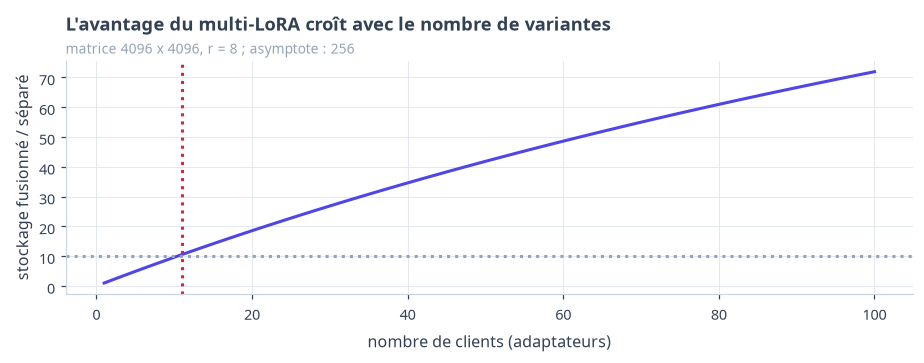

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.plot(n, ratio, color=INDIGO)
ax.axhline(10, color=GRAY, ls=":"); ax.axvline(n[np.argmax(ratio > 10)], color=ROSE, ls=":")
ax.set_xlabel("nombre de clients (adaptateurs)"); ax.set_ylabel("stockage fusionné / séparé")
c7.title_sub(ax, "L'avantage du multi-LoRA croît avec le nombre de variantes", "matrice 4096 x 4096, r = 8 ; asymptote : 256")
plt.tight_layout(); plt.show()

> **À retenir.** $r(d_{in}+d_{out})$ par matrice et par couche : un calcul simple, à
> refaire soi-même plutôt que de recopier un tableau. Le stockage multi-LoRA tend vers un
> rapport $d_{in} d_{out} / (r(d_{in}+d_{out}))$ (ici 256).

## Exercice 7.8 : LoRA à la main

**Énoncé.** Pour une couche LoRA $y = Wx + \frac{\alpha}{r} BAx$ avec $W$ gelée :

1. Exprimer $\partial L / \partial A$ et $\partial L / \partial B$ en fonction de
   $g = \partial L / \partial y$. En déduire pourquoi on n'initialise pas $A$ **et** $B$ à
   zéro, et pourquoi initialiser **l'une** des deux à zéro suffit à démarrer du modèle de base.
2. Montrer que $\text{rang}(BA) \le r$.
3. Compter les opérations (multiplications-additions) par token pour la version non
   fusionnée et la version fusionnée, pour $d_{in} = d_{out} = 4096$ et $r = 8$.
4. Vérifier 1 et 2 numériquement.

**Rappels.** Cours 3, section 3 : `c7.make_lora_linear_class` initialise $A$ aléatoirement
et $B$ à zéro.

**Solution.**

*1.* Avec $u = Ax$ et $c = \alpha/r$ : $\partial L/\partial B = c\, g\, u^\top = c\, g\, (Ax)^\top$ et
$\partial L/\partial A = c\, B^\top g\, x^\top$. Si $A = B = 0$, les deux gradients sont nuls :
l'adaptateur ne bouge **jamais** (point selle). Si seulement $B = 0$, alors $BA = 0$
(départ exact du modèle de base) mais $\partial L/\partial B = c\, g\,(Ax)^\top \ne 0$ : $B$
apprend dès le premier pas, puis $A$ reçoit un gradient non nul.

*2.* L'image de $BA$ est incluse dans celle de $B$, engendrée par ses $r$ colonnes :
$\text{rang}(BA) \le \text{rang}(B) \le r$.

*3.* Fusionnée : $d_{in} d_{out} = 16{,}8$ M opérations par token. Non fusionnée :
$d_{in}d_{out} + r\,d_{in} + r\,d_{out} = 16{,}8\text{ M} + 65\,536$, soit +0,4 % d'opérations.
Le surcoût observé en pratique (cours 3, section 7) vient surtout des lancements de
noyaux supplémentaires et des petites matrices peu efficaces sur GPU, pas du nombre
d'opérations.

In [4]:
LoRALinear = c7.make_lora_linear_class()
torch.manual_seed(0)
x = torch.randn(16, 32); target = torch.randn(16, 24)
rows = []
for init in ["A aléatoire, B = 0", "A = 0, B = 0", "A et B aléatoires"]:
    lay = LoRALinear(torch.nn.Linear(32, 24, bias=False), r=4, alpha=8)
    with torch.no_grad():
        if init == "A = 0, B = 0":
            lay.A.zero_()
        if init == "A et B aléatoires":
            lay.B.normal_(0, 0.1)
    out0 = lay(x)
    loss = ((out0 - target) ** 2).mean(); loss.backward()
    rows.append({"initialisation": init, "écart initial au modèle de base": (out0 - lay.base(x)).abs().max().item(),
                 "||dL/dA||": lay.A.grad.norm().item(), "||dL/dB||": lay.B.grad.norm().item()})
display(pd.DataFrame(rows).set_index("initialisation"))
ranks = [torch.linalg.matrix_rank(torch.randn(64, r) @ torch.randn(r, 64)).item() for r in [1, 2, 4, 8, 16]]
print("rang de BA pour r = 1, 2, 4, 8, 16 :", ranks)
d_, r_ = 4096, 8
print(f"opérations par token : fusionnée {d_ * d_:,}, non fusionnée {d_ * d_ + r_ * 2 * d_:,} (+{r_ * 2 * d_ / d_ ** 2:.2%})".replace(",", " "))

,écart initial au modèle de base,||dL/dA||,||dL/dB||
initialisation,,,
"A aléatoire, B = 0",0.000000,0.000000,0.196613
"A = 0, B = 0",0.000000,0.000000,0.000000
A et B aléatoires,0.874478,0.296231,0.321837


rang de BA pour r = 1, 2, 4, 8, 16 : [1, 2, 4, 8, 16]
opérations par token : fusionnée 16 777 216  non fusionnée 16 842 752 (+0.39%)


**Vérification.** Le tableau confirme l'analyse : seule l'initialisation « $B = 0$, $A$
aléatoire » part exactement du modèle de base **et** reçoit un gradient non nul (sur $B$).
Avec $A$ et $B$ aléatoires, on apprendrait aussi, mais le modèle de départ serait perturbé.

> **À retenir.** $B = 0$ et $A$ aléatoire : départ exact du modèle de base et apprentissage
> immédiat. Le rang de la mise à jour est borné par $r$, et la version non fusionnée ne
> coûte que $r(d_{in}+d_{out})$ opérations de plus par token.

## Exercice 7.9 : Quel rang pour notre tâche ?

**Énoncé.** Sur la tâche des tickets (cours 3, section 6), entraîner des LoRA de rang 1,
4 et 32 (avec $\alpha = 2r$, mêmes données, 2 époques) et comparer : paramètres
entraînables, perte de validation, format et catégorie sur les formulations inédites.
Conclure sur le choix du rang à la lumière de la section *LoRA configurations*.

**Rappels.** Le livre rapporte qu'un rang de 4 à 64 suffit généralement et qu'augmenter
$r$ au-delà apporte peu (voire nuit par sur-apprentissage) ; cours 3, section 3 : le rang
doit égaler la complexité de la mise à jour nécessaire.

**Solution.** Deux effets s'opposent. D'un côté, la tâche (imposer un format, choisir
parmi quelques valeurs) semble demander une mise à jour de faible complexité, ce qui
plaide pour un petit rang. De l'autre, avec $\alpha = 2r$ le facteur d'échelle est le même
pour tous les rangs, mais un adaptateur de rang 1 n'a que 0,55 M paramètres pour absorber
le gradient : avec un budget fixe de 40 pas, il peut ne pas avoir le temps de converger.
Seule l'expérience tranche.

In [5]:
train_t = c7.make_tickets(160, seed=0)
val_t = c7.make_tickets(24, seed=2, split="test")
test_out = c7.make_tickets(48, seed=3, split="test")
from transformers import AutoConfig

cfgq = AutoConfig.from_pretrained(llm.SMALL).to_dict()
llm.free_gpu()
rank_runs = {r: c7.gpu_retry(c7.lora_ticket_run, train_t, val=val_t, eval_sets={"hors distribution": test_out}, r=r)
             for r in [1, 4, 32]}
c7.log_vram("ex rank")
rk = pd.DataFrame({f"r = {r}": {"paramètres entraînables (M)": c7.lora_params_for_model(cfgq, c7.LORA_TARGETS, r) / 1e6,
                                "perte de validation finale": v["history"].val_loss[-1],
                                **v["scores"]["hors distribution"], "durée (s)": v["history"].seconds}
                   for r, v in rank_runs.items()}).T
rk.round(3)

,paramètres entraînables (M),perte de validation finale,format valide,catégorie exacte,urgence exacte,durée (s)
r = 1,0.550,0.662,0.146,0.146,0.104,7.352
r = 4,2.200,0.414,1.000,0.750,0.708,7.338
r = 32,17.596,0.362,1.000,0.938,1.000,7.634


**Vérification graphique.**

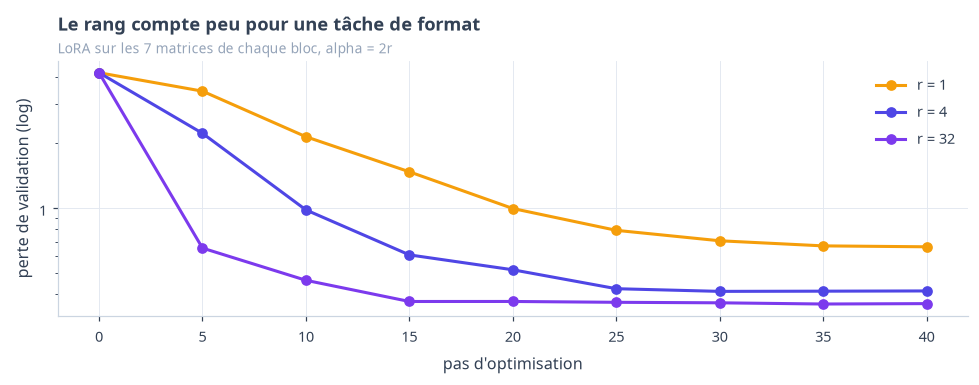

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for (r, v), col in zip(rank_runs.items(), [AMBER, INDIGO, VIOLET]):
    h = v["history"]
    ax.plot(h.val_step, h.val_loss, "o-", color=col, label=f"r = {r}")
ax.set_yscale("log"); c7.sci_log(ax, "y"); ax.set_xlabel("pas d'optimisation"); ax.set_ylabel("perte de validation (log)"); ax.legend()
c7.title_sub(ax, "Le rang compte peu pour une tâche de format", "LoRA sur les 7 matrices de chaque bloc, alpha = 2r")
plt.tight_layout(); plt.show()

Résultat à lire dans le tableau : avec ce budget d'entraînement (2 époques, 40 pas), le
rang 1 n'a pas encore appris le format, alors que les rangs 4 et 32 l'ont appris ; le rang
32 obtient ici les meilleurs scores de champs. Le livre note justement que le rang optimal
varie selon les cas (Raschka trouve $r = 256$ optimal sur ses tâches) : un « petit rang
suffit » n'est pas une loi. Deux précautions avant de conclure : avec 48 tickets, quelques
points d'écart ne sont pas significatifs, et un rang 1 entraîné plus longtemps (ou avec un
taux plus élevé) rattraperait sans doute une partie du retard. Le rang interagit donc avec
le taux d'apprentissage et le nombre de pas : on le règle avec eux, sur l'évaluation.

> **À retenir.** Le rang se règle expérimentalement, avec le taux d'apprentissage et le
> budget d'entraînement : un rang trop faible peut ne pas converger dans le temps imparti.
> 8 à 32 est un point de départ raisonnable ; le coût mémoire de LoRA reste faible même à
> rang 32 (17,6 M paramètres ici).